# Notebook 6 — Final Analysis & Results

## Nexar Collision Prediction

This notebook is the **analysis stage** of the project.

The modelling work has already been completed in the previous notebooks:

- **Model 0:** Naive baseline
- **Model 1:** Classical optical-flow baseline
- **Model 2:** CNN + LSTM learned temporal model

The purpose of this notebook is to turn those experiments into a clean, reproducible set of:

1. Final result tables
2. AP vs TTE analysis
3. ROC-AUC vs TTE analysis
4. Precision/Recall/F1 analysis
5. CNN + LSTM training curves
6. Relative improvement calculations
7. CSV result files for the final report
8. A concise preliminary interpretation

### Important

The primary optical-flow baseline used here is **`optical_flow`**, not `optical_flow_scaled`.

The scaled optical-flow experiment is retained separately as an additional/variant result and is not used as the primary baseline in the main comparison.


## 1. Experimental setup

The evaluation uses three prediction horizons:

- **TTE = 0.5 seconds**
- **TTE = 1.0 seconds**
- **TTE = 1.5 seconds**

TTE means **time-to-event**: how far before the collision the prediction must be made.

The primary evaluation metric is **Average Precision (AP)**. ROC-AUC, precision, recall, and F1 are included as secondary metrics.

The validation set contains 300 examples at each TTE, except the training set at TTE=1.5 where one invalid positive clip was removed, leaving 1199 training examples.


In [1]:
# Imports and project configuration

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path(".")
RESULTS_DIR = PROJECT_DIR / "results" / "final_analysis"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 6)

print("Results directory:", RESULTS_DIR.resolve())


Results directory: /Users/rameez/Documents/Wits Stuff/Honours/Computer Vision/nexar-collision-prediction/results/final_analysis


## 2. Enter the official primary results

These are the results produced by the completed baseline and CNN+LSTM notebooks.

The main comparison deliberately uses:

- Naive
- Optical Flow
- CNN + LSTM

The `optical_flow_scaled` variant is handled later as an additional analysis.


In [2]:
# Official primary results
# These values come from the completed experiments.

primary_results = pd.DataFrame([
    # Naive
    ["naive", 0.5, 0.500000, 0.500000, 0.500000, 1.000000, 0.666667],
    ["naive", 1.0, 0.500000, 0.500000, 0.500000, 1.000000, 0.666667],
    ["naive", 1.5, 0.500000, 0.500000, 0.500000, 1.000000, 0.666667],

    # Optical flow
    ["optical_flow", 0.5, 0.582072, 0.586933, 0.559055, 0.473333, 0.512635],
    ["optical_flow", 1.0, 0.569201, 0.592667, 0.545455, 0.480000, 0.510638],
    ["optical_flow", 1.5, 0.568029, 0.575956, 0.554745, 0.506667, 0.529617],

    # CNN + LSTM
    ["cnn_lstm", 0.5, 0.793449, 0.780578, 0.713235, 0.646667, 0.678322],
    ["cnn_lstm", 1.0, 0.773729, 0.746578, 0.619565, 0.760000, 0.682635],
    ["cnn_lstm", 1.5, 0.739205, 0.709111, 0.649635, 0.593333, 0.620209],
], columns=[
    "model", "tte", "AP", "ROC_AUC", "Precision", "Recall", "F1"
])

model_display = {
    "naive": "Naive",
    "optical_flow": "Optical Flow",
    "cnn_lstm": "CNN + LSTM",
}

primary_results["model_display"] = primary_results["model"].map(model_display)

primary_results


,model,tte,AP,ROC_AUC,Precision,Recall,F1,model_display
0,naive,0.5,0.500000,0.500000,0.500000,1.000000,0.666667,Naive
1,naive,1.0,0.500000,0.500000,0.500000,1.000000,0.666667,Naive
2,naive,1.5,0.500000,0.500000,0.500000,1.000000,0.666667,Naive
3,optical_flow,0.5,0.582072,0.586933,0.559055,0.473333,0.512635,Optical Flow
4,optical_flow,1.0,0.569201,0.592667,0.545455,0.480000,0.510638,Optical Flow
5,optical_flow,1.5,0.568029,0.575956,0.554745,0.506667,0.529617,Optical Flow
6,cnn_lstm,0.5,0.793449,0.780578,0.713235,0.646667,0.678322,CNN + LSTM
7,cnn_lstm,1.0,0.773729,0.746578,0.619565,0.760000,0.682635,CNN + LSTM
8,cnn_lstm,1.5,0.739205,0.709111,0.649635,0.593333,0.620209,CNN + LSTM


## 3. Final primary comparison table

This is the main table that can later be adapted for the report.

AP is the primary metric, while the other metrics provide additional context.


In [3]:
final_table = (
    primary_results[
        ["model_display", "tte", "AP", "ROC_AUC", "Precision", "Recall", "F1"]
    ]
    .rename(columns={"model_display": "Model", "tte": "TTE"})
    .sort_values(["TTE", "Model"])
    .reset_index(drop=True)
)

final_table


,Model,TTE,AP,ROC_AUC,Precision,Recall,F1
0,CNN + LSTM,0.5,0.793449,0.780578,0.713235,0.646667,0.678322
1,Naive,0.5,0.500000,0.500000,0.500000,1.000000,0.666667
2,Optical Flow,0.5,0.582072,0.586933,0.559055,0.473333,0.512635
3,CNN + LSTM,1.0,0.773729,0.746578,0.619565,0.760000,0.682635
4,Naive,1.0,0.500000,0.500000,0.500000,1.000000,0.666667
5,Optical Flow,1.0,0.569201,0.592667,0.545455,0.480000,0.510638
6,CNN + LSTM,1.5,0.739205,0.709111,0.649635,0.593333,0.620209
7,Naive,1.5,0.500000,0.500000,0.500000,1.000000,0.666667
8,Optical Flow,1.5,0.568029,0.575956,0.554745,0.506667,0.529617


In [4]:
# Save the main result table

main_results_path = RESULTS_DIR / "final_primary_results.csv"
primary_results.to_csv(main_results_path, index=False)

print("Saved:", main_results_path)


Saved: results/final_analysis/final_primary_results.csv


## 4. AP versus prediction horizon

This is the most important project figure.

The original project proposal asks whether collision-prediction performance degrades as the model is required to predict further before the collision.

We therefore plot AP against TTE for all three models.


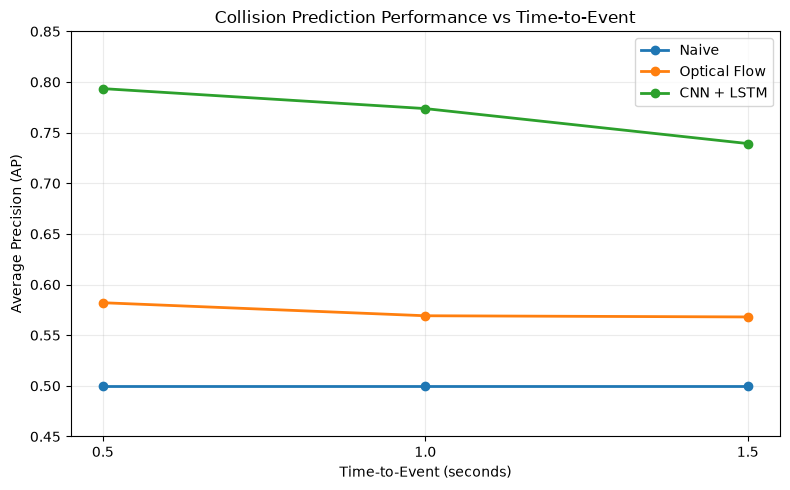

Saved: results/final_analysis/ap_vs_tte.png


In [5]:
# AP vs TTE

plt.figure(figsize=(8, 5))

for model in ["naive", "optical_flow", "cnn_lstm"]:
    subset = primary_results[primary_results["model"] == model].sort_values("tte")
    plt.plot(
        subset["tte"],
        subset["AP"],
        marker="o",
        linewidth=2,
        label=model_display[model],
    )

plt.xlabel("Time-to-Event (seconds)")
plt.ylabel("Average Precision (AP)")
plt.title("Collision Prediction Performance vs Time-to-Event")
plt.xticks([0.5, 1.0, 1.5])
plt.ylim(0.45, 0.85)
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()

ap_plot_path = RESULTS_DIR / "ap_vs_tte.png"
plt.savefig(ap_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", ap_plot_path)


### AP degradation for CNN + LSTM

For the learned model:

- 0.5 s: AP = 0.793449
- 1.0 s: AP = 0.773729
- 1.5 s: AP = 0.739205

This gives the primary degradation curve for the project.


In [6]:
cnn = primary_results[primary_results["model"] == "cnn_lstm"].sort_values("tte")

ap_05 = cnn.loc[cnn["tte"] == 0.5, "AP"].iloc[0]
ap_10 = cnn.loc[cnn["tte"] == 1.0, "AP"].iloc[0]
ap_15 = cnn.loc[cnn["tte"] == 1.5, "AP"].iloc[0]

absolute_drop_05_to_15 = ap_05 - ap_15
relative_drop_05_to_15 = (ap_05 - ap_15) / ap_05 * 100

print(f"CNN + LSTM AP at 0.5s: {ap_05:.6f}")
print(f"CNN + LSTM AP at 1.0s: {ap_10:.6f}")
print(f"CNN + LSTM AP at 1.5s: {ap_15:.6f}")
print()
print(f"Absolute AP drop (0.5s -> 1.5s): {absolute_drop_05_to_15:.6f}")
print(f"Relative AP drop (0.5s -> 1.5s): {relative_drop_05_to_15:.2f}%")


CNN + LSTM AP at 0.5s: 0.793449
CNN + LSTM AP at 1.0s: 0.773729
CNN + LSTM AP at 1.5s: 0.739205

Absolute AP drop (0.5s -> 1.5s): 0.054244
Relative AP drop (0.5s -> 1.5s): 6.84%


## 5. ROC-AUC versus prediction horizon

ROC-AUC is a secondary metric.

Unlike AP, it measures ranking/discrimination across thresholds using the ROC curve.


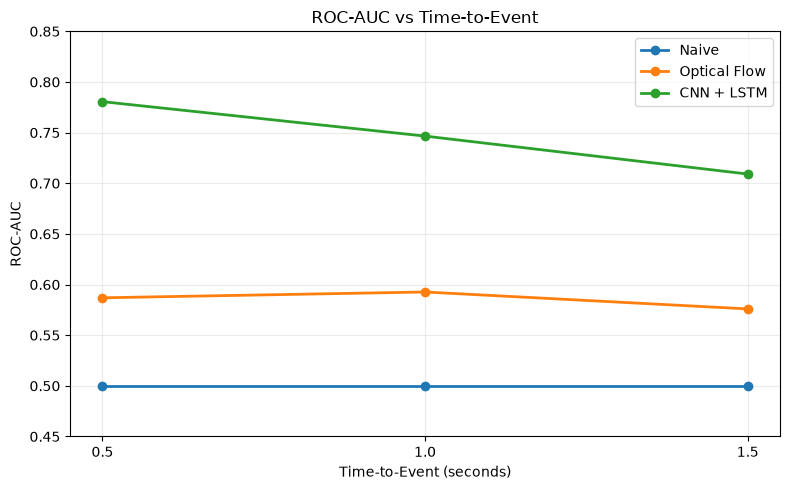

Saved: results/final_analysis/roc_auc_vs_tte.png


In [7]:
# ROC-AUC vs TTE

plt.figure(figsize=(8, 5))

for model in ["naive", "optical_flow", "cnn_lstm"]:
    subset = primary_results[primary_results["model"] == model].sort_values("tte")
    plt.plot(
        subset["tte"],
        subset["ROC_AUC"],
        marker="o",
        linewidth=2,
        label=model_display[model],
    )

plt.xlabel("Time-to-Event (seconds)")
plt.ylabel("ROC-AUC")
plt.title("ROC-AUC vs Time-to-Event")
plt.xticks([0.5, 1.0, 1.5])
plt.ylim(0.45, 0.85)
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()

roc_plot_path = RESULTS_DIR / "roc_auc_vs_tte.png"
plt.savefig(roc_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", roc_plot_path)


## 6. Precision, Recall and F1

These metrics are secondary because the project proposal identifies AP as the primary evaluation measure.

They are still useful for understanding the classification behaviour at the selected operating threshold.


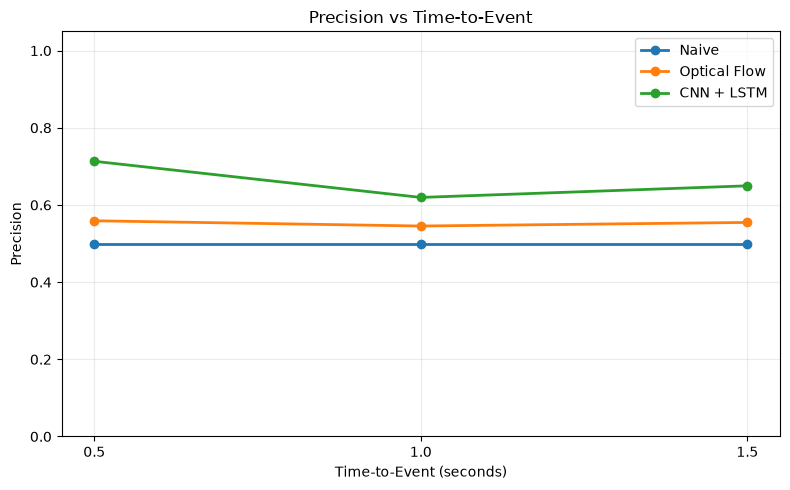

Saved: results/final_analysis/precision_vs_tte.png


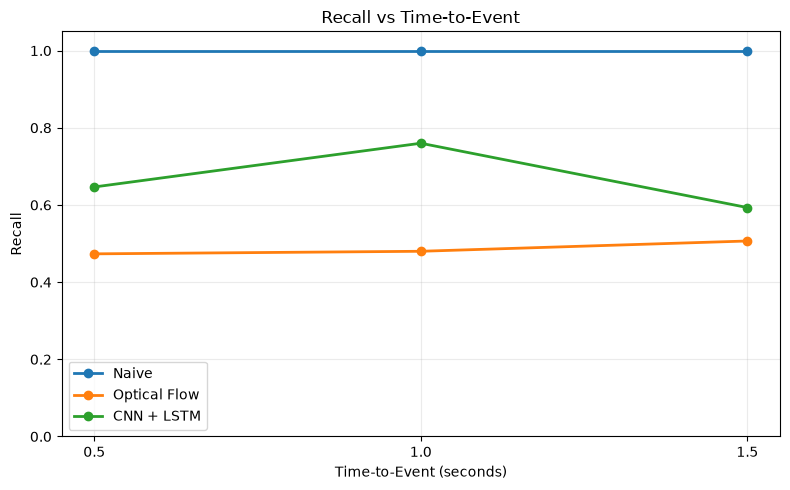

Saved: results/final_analysis/recall_vs_tte.png


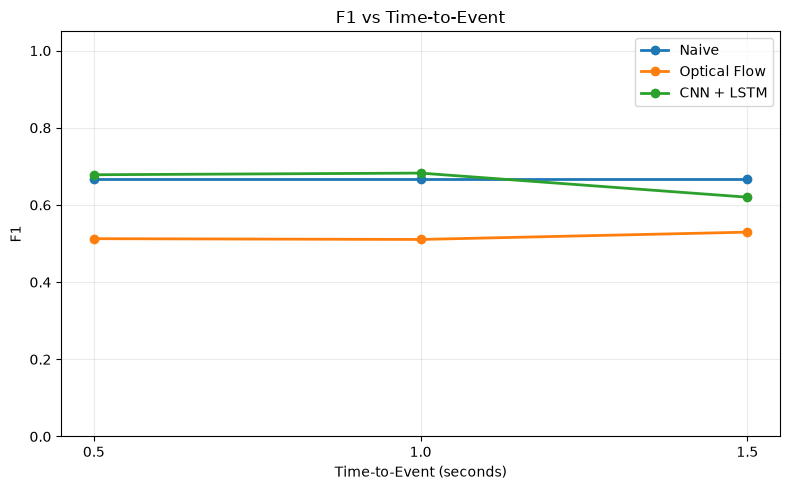

Saved: results/final_analysis/f1_vs_tte.png


In [8]:
metrics = ["Precision", "Recall", "F1"]

for metric in metrics:
    plt.figure(figsize=(8, 5))

    for model in ["naive", "optical_flow", "cnn_lstm"]:
        subset = primary_results[primary_results["model"] == model].sort_values("tte")
        plt.plot(
            subset["tte"],
            subset[metric],
            marker="o",
            linewidth=2,
            label=model_display[model],
        )

    plt.xlabel("Time-to-Event (seconds)")
    plt.ylabel(metric)
    plt.title(f"{metric} vs Time-to-Event")
    plt.xticks([0.5, 1.0, 1.5])
    plt.ylim(0.0, 1.05)
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.tight_layout()

    output_path = RESULTS_DIR / f"{metric.lower()}_vs_tte.png"
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", output_path)


## 7. CNN + LSTM training history

The best validation AP occurred at:

- **TTE 0.5 s:** epoch 4
- **TTE 1.0 s:** epoch 5
- **TTE 1.5 s:** epoch 2

The following histories reproduce the validation AP and ROC-AUC values recorded during Notebook 5 training.


In [9]:
training_history = {
    0.5: {
        "epoch": list(range(1, 11)),
        "train_loss": [0.6448, 0.5835, 0.5598, 0.5447, 0.5287, 0.5102, 0.4861, 0.4675, 0.4478, 0.4302],
        "val_ap": [0.7652, 0.7872, 0.7873, 0.7934, 0.7916, 0.7912, 0.7886, 0.7892, 0.7744, 0.7722],
        "val_roc_auc": [0.7599, 0.7780, 0.7791, 0.7806, 0.7814, 0.7749, 0.7753, 0.7732, 0.7574, 0.7600],
    },
    1.0: {
        "epoch": list(range(1, 11)),
        "train_loss": [0.6453, 0.6054, 0.5664, 0.5683, 0.5571, 0.5288, 0.5117, 0.5067, 0.4689, 0.4856],
        "val_ap": [0.7580, 0.7642, 0.7708, 0.7606, 0.7737, 0.7685, 0.7587, 0.7493, 0.7544, 0.7532],
        "val_roc_auc": [0.7534, 0.7433, 0.7472, 0.7405, 0.7466, 0.7394, 0.7298, 0.7190, 0.7164, 0.7195],
    },
    1.5: {
        "epoch": list(range(1, 11)),
        "train_loss": [0.6529, 0.6106, 0.5913, 0.5690, 0.5603, 0.5310, 0.5311, 0.5366, 0.5099, 0.4804],
        "val_ap": [0.7156, 0.7392, 0.7294, 0.7288, 0.7268, 0.7179, 0.7242, 0.6990, 0.7024, 0.6964],
        "val_roc_auc": [0.7154, 0.7091, 0.7123, 0.6978, 0.6932, 0.6889, 0.6889, 0.6819, 0.6840, 0.6762],
    },
}


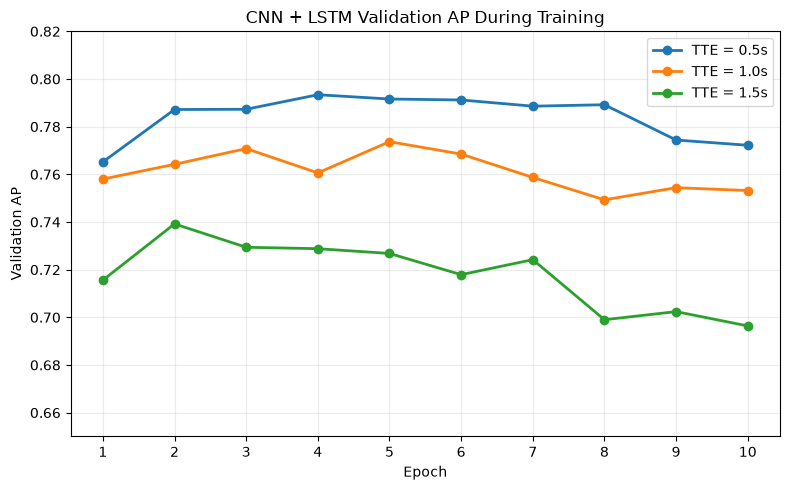

Saved: results/final_analysis/cnn_lstm_validation_ap_training.png


In [10]:
# Plot validation AP training curves

plt.figure(figsize=(8, 5))

for tte, history in training_history.items():
    plt.plot(
        history["epoch"],
        history["val_ap"],
        marker="o",
        linewidth=2,
        label=f"TTE = {tte:.1f}s",
    )

plt.xlabel("Epoch")
plt.ylabel("Validation AP")
plt.title("CNN + LSTM Validation AP During Training")
plt.xticks(range(1, 11))
plt.ylim(0.65, 0.82)
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()

path = RESULTS_DIR / "cnn_lstm_validation_ap_training.png"
plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", path)


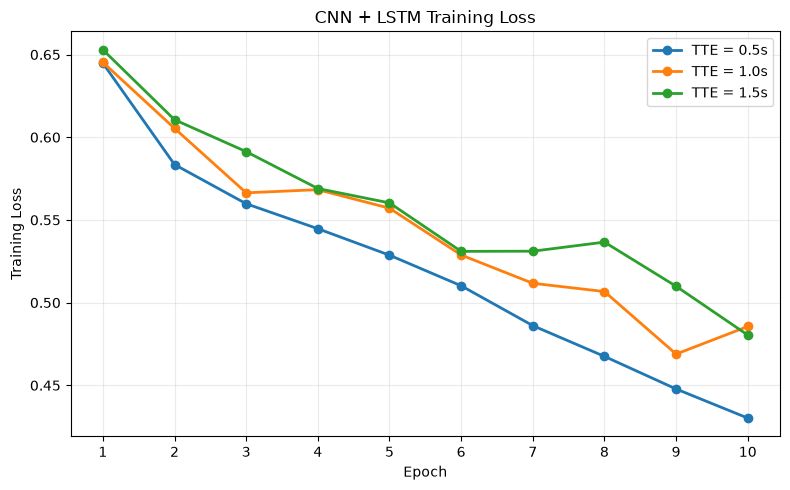

Saved: results/final_analysis/cnn_lstm_training_loss.png


In [11]:
# Plot training loss

plt.figure(figsize=(8, 5))

for tte, history in training_history.items():
    plt.plot(
        history["epoch"],
        history["train_loss"],
        marker="o",
        linewidth=2,
        label=f"TTE = {tte:.1f}s",
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("CNN + LSTM Training Loss")
plt.xticks(range(1, 11))
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()

path = RESULTS_DIR / "cnn_lstm_training_loss.png"
plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", path)


## 8. Relative improvement over the baselines

This section quantifies the AP difference between CNN + LSTM and the two reference systems.

The calculation is:

\[
\text{Relative improvement} =
\frac{AP_{CNN+LSTM} - AP_{baseline}}
{AP_{baseline}} \times 100
\]

This is descriptive only; AP itself remains the primary result.


In [12]:
# Calculate CNN + LSTM AP improvements

wide_ap = primary_results.pivot(
    index="tte",
    columns="model",
    values="AP"
).reset_index()

wide_ap["cnn_vs_naive_relative_percent"] = (
    (wide_ap["cnn_lstm"] - wide_ap["naive"])
    / wide_ap["naive"]
    * 100
)

wide_ap["cnn_vs_optical_flow_relative_percent"] = (
    (wide_ap["cnn_lstm"] - wide_ap["optical_flow"])
    / wide_ap["optical_flow"]
    * 100
)

wide_ap


model,tte,cnn_lstm,naive,optical_flow,cnn_vs_naive_relative_percent,cnn_vs_optical_flow_relative_percent
0,0.5,0.793449,0.5,0.582072,58.6898,36.314580
1,1.0,0.773729,0.5,0.569201,54.7458,35.932474
2,1.5,0.739205,0.5,0.568029,47.8410,30.135081


In [13]:
# Print a report-friendly summary

for _, row in wide_ap.iterrows():
    print(
        f"TTE={row['tte']:.1f}s | "
        f"CNN+LSTM AP={row['cnn_lstm']:.4f} | "
        f"Optical Flow AP={row['optical_flow']:.4f} | "
        f"Naive AP={row['naive']:.4f} | "
        f"CNN vs Optical Flow={row['cnn_vs_optical_flow_relative_percent']:.2f}% | "
        f"CNN vs Naive={row['cnn_vs_naive_relative_percent']:.2f}%"
    )


TTE=0.5s | CNN+LSTM AP=0.7934 | Optical Flow AP=0.5821 | Naive AP=0.5000 | CNN vs Optical Flow=36.31% | CNN vs Naive=58.69%
TTE=1.0s | CNN+LSTM AP=0.7737 | Optical Flow AP=0.5692 | Naive AP=0.5000 | CNN vs Optical Flow=35.93% | CNN vs Naive=54.75%
TTE=1.5s | CNN+LSTM AP=0.7392 | Optical Flow AP=0.5680 | Naive AP=0.5000 | CNN vs Optical Flow=30.14% | CNN vs Naive=47.84%


## 9. Additional optical-flow variant

The project also tested a scaled version of the optical-flow features.

This is **not** used as the primary baseline.

It is retained here so that the experiment is documented rather than discarded.


In [14]:
optical_flow_scaled = pd.DataFrame([
    ["optical_flow_scaled", 0.5, 0.574508, 0.588711, 0.543307, 0.460000, 0.498195],
    ["optical_flow_scaled", 1.0, 0.575785, 0.591511, 0.530303, 0.466667, 0.496454],
    ["optical_flow_scaled", 1.5, 0.568349, 0.573911, 0.544118, 0.493333, 0.517483],
], columns=[
    "model", "tte", "AP", "ROC_AUC", "Precision", "Recall", "F1"
])

optical_flow_scaled


,model,tte,AP,ROC_AUC,Precision,Recall,F1
0,optical_flow_scaled,0.5,0.574508,0.588711,0.543307,0.460000,0.498195
1,optical_flow_scaled,1.0,0.575785,0.591511,0.530303,0.466667,0.496454
2,optical_flow_scaled,1.5,0.568349,0.573911,0.544118,0.493333,0.517483


In [15]:
# Compare the two optical-flow variants

flow_compare = primary_results[
    primary_results["model"] == "optical_flow"
][["tte", "AP", "ROC_AUC"]].merge(
    optical_flow_scaled[["tte", "AP", "ROC_AUC"]],
    on="tte",
    suffixes=("_regular", "_scaled")
)

flow_compare["AP_scaled_minus_regular"] = (
    flow_compare["AP_scaled"] - flow_compare["AP_regular"]
)

flow_compare


,tte,AP_regular,ROC_AUC_regular,AP_scaled,ROC_AUC_scaled,AP_scaled_minus_regular
0,0.5,0.582072,0.586933,0.574508,0.588711,-0.007564
1,1.0,0.569201,0.592667,0.575785,0.591511,0.006584
2,1.5,0.568029,0.575956,0.568349,0.573911,0.000320


## 10. Final numerical summary

This section extracts the key numbers that are likely to be useful in the final report.


In [16]:
summary_rows = []

for tte in [0.5, 1.0, 1.5]:
    row = primary_results[primary_results["tte"] == tte]

    naive_ap = row[row["model"] == "naive"]["AP"].iloc[0]
    flow_ap = row[row["model"] == "optical_flow"]["AP"].iloc[0]
    cnn_ap = row[row["model"] == "cnn_lstm"]["AP"].iloc[0]

    summary_rows.append({
        "TTE": tte,
        "Naive_AP": naive_ap,
        "Optical_Flow_AP": flow_ap,
        "CNN_LSTM_AP": cnn_ap,
        "CNN_minus_Optical_Flow_AP": cnn_ap - flow_ap,
        "CNN_relative_improvement_vs_Optical_Flow_percent":
            (cnn_ap - flow_ap) / flow_ap * 100,
    })

summary = pd.DataFrame(summary_rows)

summary


,TTE,Naive_AP,Optical_Flow_AP,CNN_LSTM_AP,CNN_minus_Optical_Flow_AP,CNN_relative_improvement_vs_Optical_Flow_percent
0,0.5,0.5,0.582072,0.793449,0.211377,36.314580
1,1.0,0.5,0.569201,0.773729,0.204528,35.932474
2,1.5,0.5,0.568029,0.739205,0.171176,30.135081


In [17]:
# Save all analysis tables

summary.to_csv(
    RESULTS_DIR / "report_summary.csv",
    index=False
)

wide_ap.to_csv(
    RESULTS_DIR / "ap_comparison.csv",
    index=False
)

optical_flow_scaled.to_csv(
    RESULTS_DIR / "optical_flow_scaled_results.csv",
    index=False
)

print("Saved analysis CSV files to:")
print(RESULTS_DIR.resolve())


Saved analysis CSV files to:
/Users/rameez/Documents/Wits Stuff/Honours/Computer Vision/nexar-collision-prediction/results/final_analysis


# 11. Preliminary interpretation

Based on the completed experiments, the following observations are supported by the current validation results:

### Observation 1 — The learned model substantially exceeds the naive baseline

CNN + LSTM achieves AP values of:

- 0.7934 at 0.5 s
- 0.7737 at 1.0 s
- 0.7392 at 1.5 s

The naive baseline has AP = 0.5 at all three horizons.

### Observation 2 — CNN + LSTM exceeds the classical optical-flow baseline

The primary optical-flow AP values are:

- 0.5821 at 0.5 s
- 0.5692 at 1.0 s
- 0.5680 at 1.5 s

The CNN + LSTM therefore provides substantially higher AP at every tested TTE.

### Observation 3 — Performance decreases as the prediction horizon increases

CNN + LSTM AP decreases from 0.7934 at 0.5 s to 0.7392 at 1.5 s.

This is consistent with the prediction task becoming harder as the model must make a prediction further before the collision.

### Observation 4 — The learned model begins to lose validation performance after its best epoch

The best epochs were:

- 0.5 s → epoch 4
- 1.0 s → epoch 5
- 1.5 s → epoch 2

Training loss continued to decrease after these points while validation AP generally declined. This indicates that the current 10-epoch training schedule can produce overfitting.

### Important limitation

These are results from the current experimental runs. Before the final report, we should still perform a small amount of validation/robustness analysis, particularly repeated runs with different random seeds if computationally practical.

We should also avoid claiming that the LSTM itself caused the improvement until we perform an appropriate ablation or comparison against a non-temporal aggregation of the same ResNet features.


# 12. What comes next

Notebook 6 is intentionally an **analysis notebook**, not another model-training notebook.

The next project stage should focus on strengthening the experimental claim rather than adding many new models.

Recommended next steps:

1. **Run a small repeated-seed experiment** for CNN + LSTM to estimate result variability.
2. **Run a temporal ablation** using the same ResNet features but without the LSTM, if computationally practical.
3. Measure **inference time**.
4. Check whether reliable environmental categories exist in the dataset before attempting environmental breakdowns.
5. Freeze the final result table.
6. Produce the final report figures and discussion.
7. Finish README/reproducibility documentation.

The central experiment is already complete:

> Compare Naive, Optical Flow, and CNN + LSTM collision prediction at 0.5, 1.0, and 1.5 seconds before the event using AP as the primary metric.
